# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import SynthinelDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 946


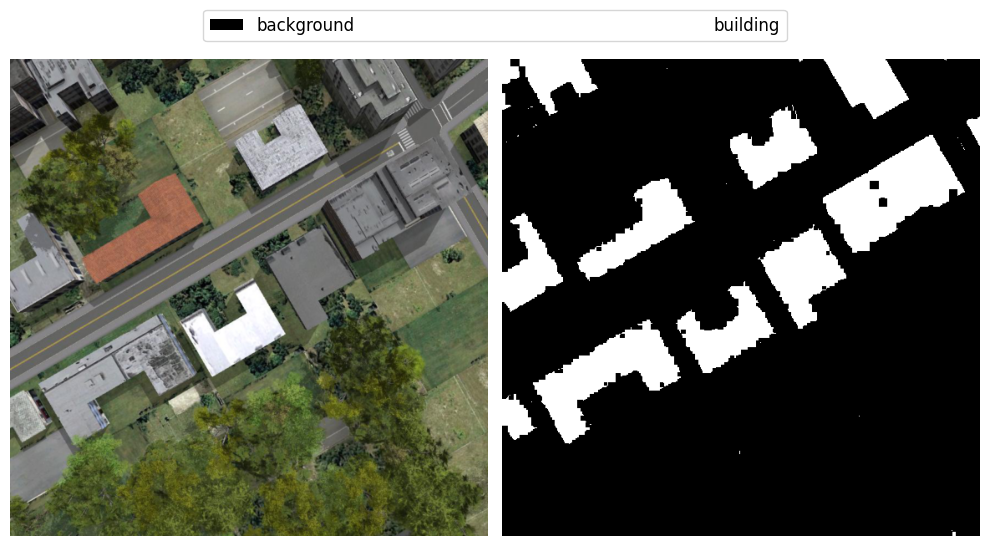

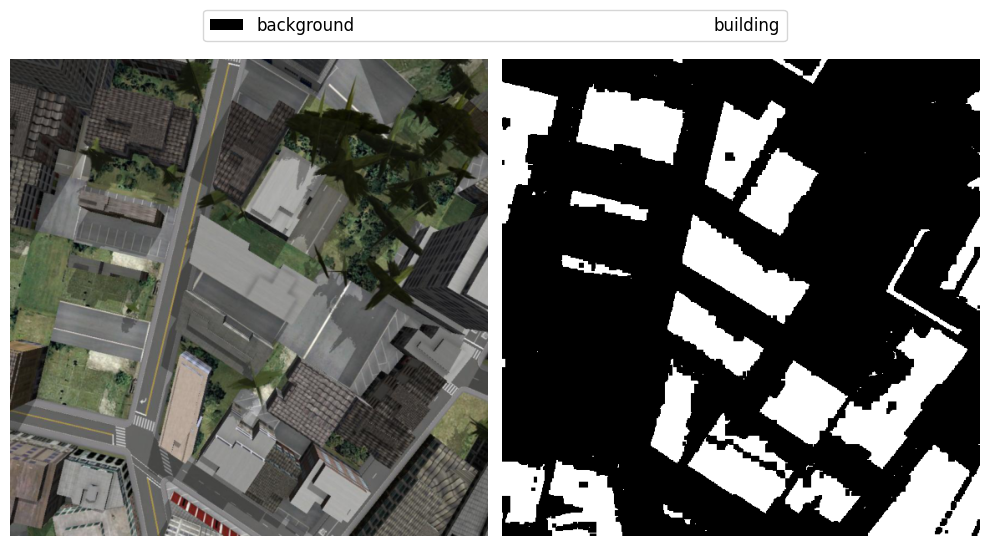

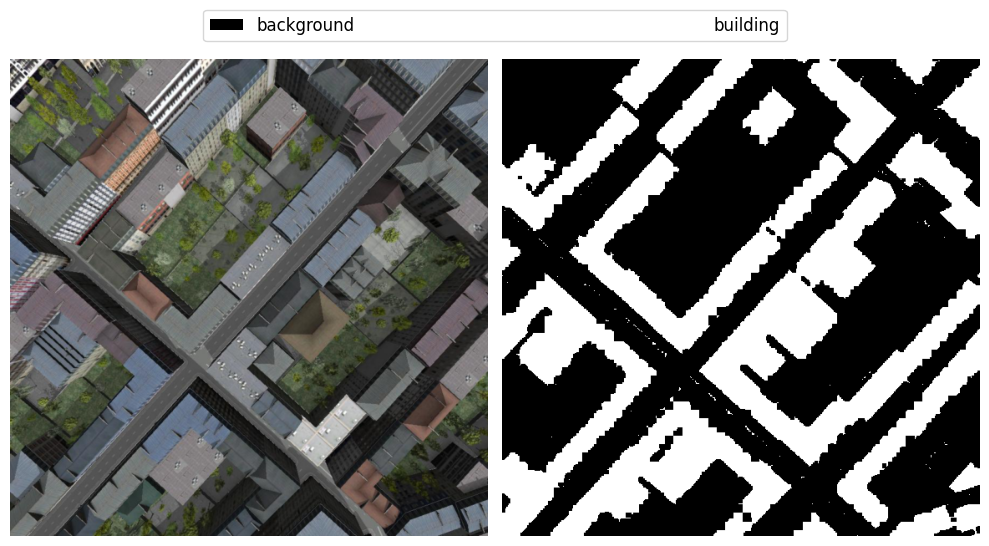

In [ ]:
dataset_config = {
    "data_dir": "./data/Synthinel"
}
dataset = SynthinelDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(1);
dataset.show_image(350);
dataset.show_image(900);

In [5]:
dataset.data_distribution_table()

,Number of pixels
background,220196939.0
building,89319125.0


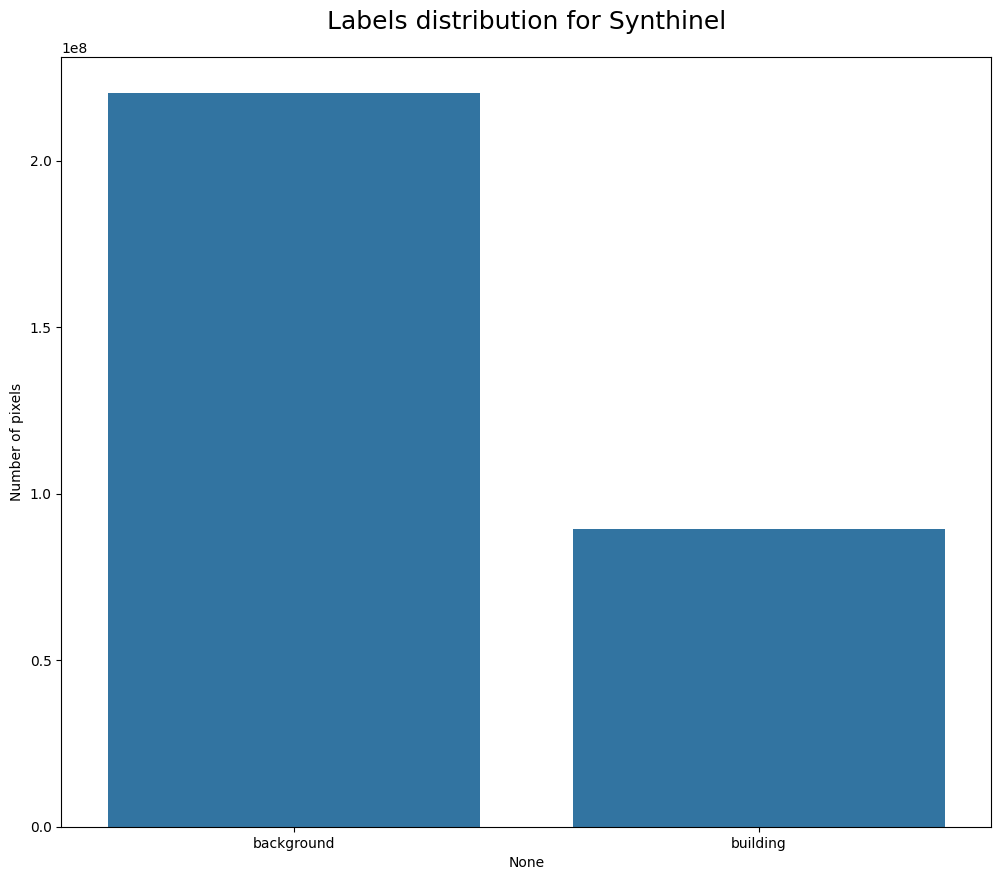

In [6]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/Synthinel",
    "csv_file": "./data/Synthinel/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = SynthinelDataset(train_dataset_config)
len(train_dataset)

758

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/Synthinel"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [37]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-04 11:48:28,131 INFO Starting training.
training: 100%|██████████| 190/190 [00:10<00:00, 18.59it/s]
2025-03-04 11:48:38,430 INFO epoch: 1, time: 10, loss:  0.29628
testing on train set: 100%|██████████| 190/190 [00:03<00:00, 54.21it/s]
2025-03-04 11:48:43,352 INFO IOU:0.7301107008023927, IOU mean:0.6960093518449522, IOU per Class:[0.83775202 0.55426668]
training: 100%|██████████| 190/190 [00:09<00:00, 19.53it/s]
2025-03-04 11:48:53,087 INFO epoch: 2, time: 10, loss:  0.17971
testing on train set: 100%|██████████| 190/190 [00:03<00:00, 54.17it/s]
2025-03-04 11:48:56,603 INFO IOU:0.796087986541351, IOU mean:0.7605654513624049, IOU per Class:[0.86841294 0.65271796]
training: 100%|██████████| 190/190 [00:10<00:00, 18.26it/s]
2025-03-04 11:49:07,012 INFO epoch: 3, time: 11, loss:  0.13728
testing on train set: 100%|██████████| 190/190 [00:03<00:00, 51.84it/s]
2025-03-04 11:49:10,691 INFO IOU:0.8133690057069809, IOU mean:0.7813028250715524, IOU per Class:[0.86944918 0.69315647]
train

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/Synthinel",
    "csv_file": "./data/Synthinel/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = SynthinelDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/Synthinel/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

94


2025-03-04 11:51:13,679 INFO Loading checkpoint /home/dragik/data/FAIR_EO/Synthinel/checkpoint.pth.tar
2025-03-04 11:51:14,029 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/Synthinel/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 24/24 [00:00<00:00, 26.89it/s]


[{'IOU': 0.8212739323507501,
  'IOU mean': 0.7857208518981649,
  'IOU per Class': array([0.88090765, 0.69053406])}]

## Predictions

2025-03-10 11:37:54,532 INFO Loading checkpoint /home/dragik/data/FAIR_EO/Synthinel/checkpoint.pth.tar
2025-03-10 11:37:54,897 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/Synthinel/checkpoint.pth.tar at epoch 11


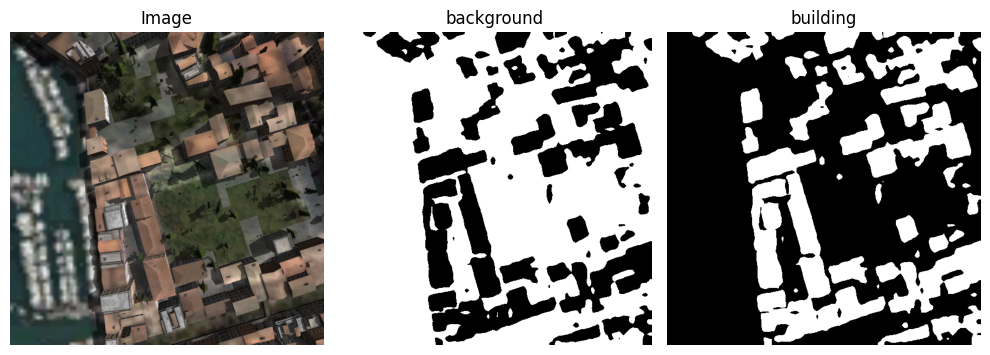

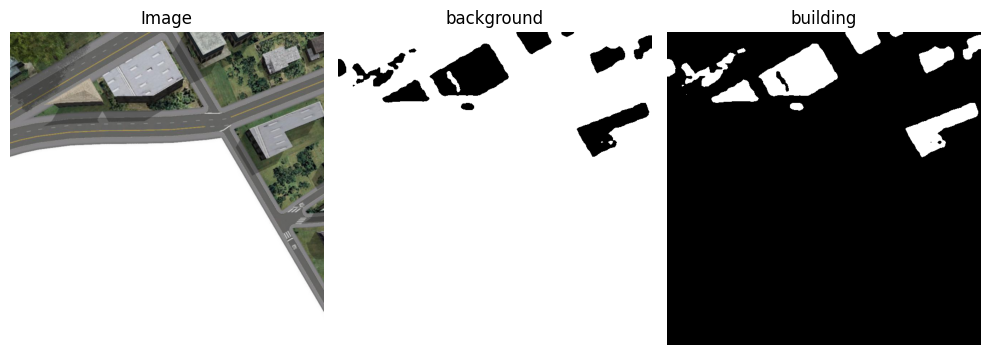

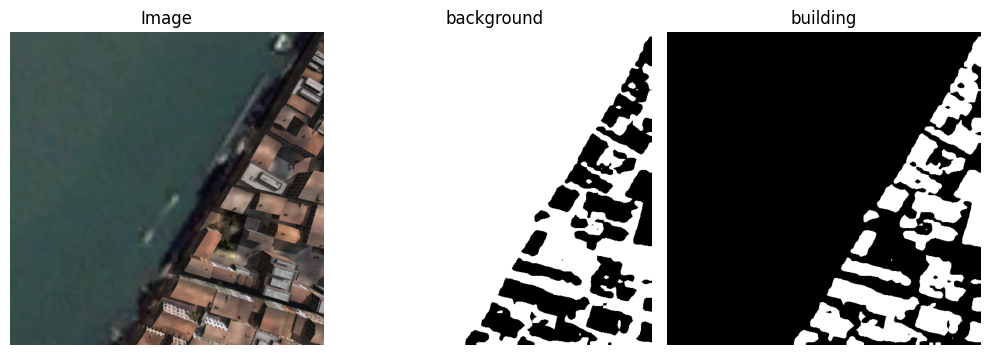

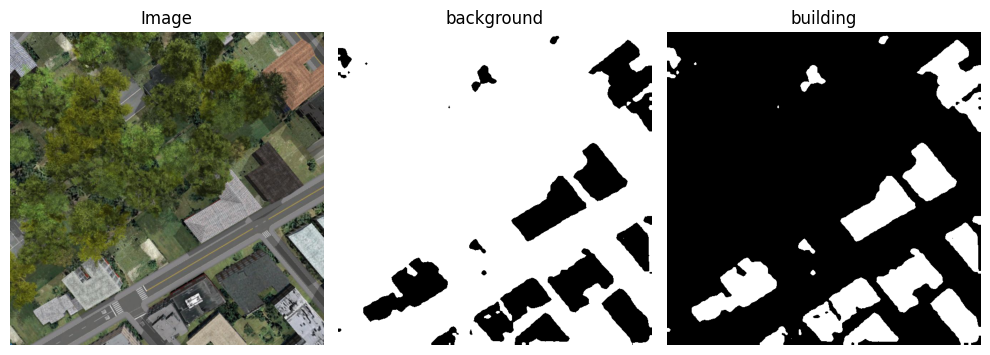

In [ ]:
model_path = "./data/Synthinel/checkpoint.pth.tar"
labels = ["background","building"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
csv_file = "./data/Synthinel/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/Synthinel/' + test_list[0])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/Synthinel/' + test_list[1])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/Synthinel/' + test_list[10])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/Synthinel/' + test_list[50])
fig = model.predict_masks(image, labels, transform)